# Projet Recherche Innovation

In [29]:
import numpy as np
import scipy
import numba
import matplotlib.pyplot as plt

print("Environnement configuré avec succès !")

Environnement configuré avec succès !


In [30]:
T_test = 1.0 #1an de maturité
n_test = 365 #par jour
t = np.linspace(0, T_test, n_test + 1)

# Brownian Motion

In [31]:
def Brownian_path(T, n): 
    dt = T/n
    W = np.zeros(n+1)
    for i in range(1,n+1): 
        W[i]=W[i-1]+np.random.normal(0,np.sqrt(dt)) 
    return W

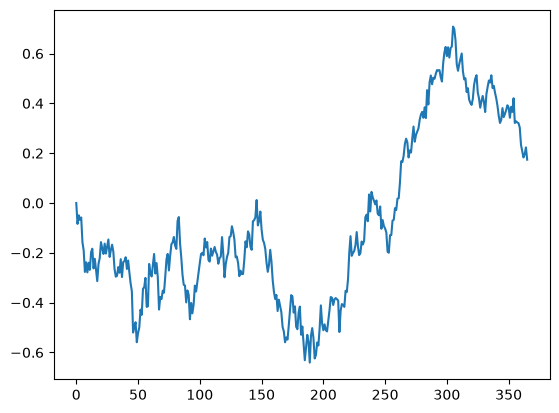

In [32]:
path=Brownian_path(T_test,n_test)
plt.plot(path)
plt.show()

# Model simulation

1. Actif sans risque

In [33]:
# parametres de simulation
r = 0.05 

# Actif sans risque
S_zero = 1
def risk_free_asset(T, n, r):
    dt = T/n
    S = np.zeros(n+1)
    S[0] = S_zero
    for i in range(1,n+1):
        S[i] = S[0] * np.exp(r * i *  dt)
    return S


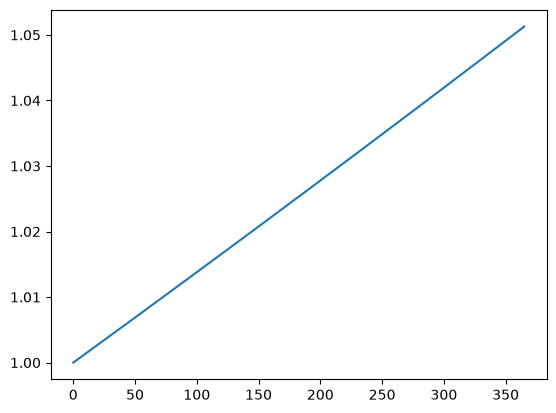

In [34]:
path=risk_free_asset(T_test,n_test,r)
plt.plot(path)
plt.show()

## Bachelier's Model

In [48]:
volatilite = 0.8
tendance = 0.12

In [36]:
def risky_asset(T, n, tendance, taux_interet, sigma):
    dt = T/n
    S = np.zeros(n+1)
    S[0] = S_zero
    brownian = Brownian_path(T,n) 
    for i in range(1,n+1):
        S[i] = S[0] + tendance * i * dt + sigma * brownian[i]
    return S

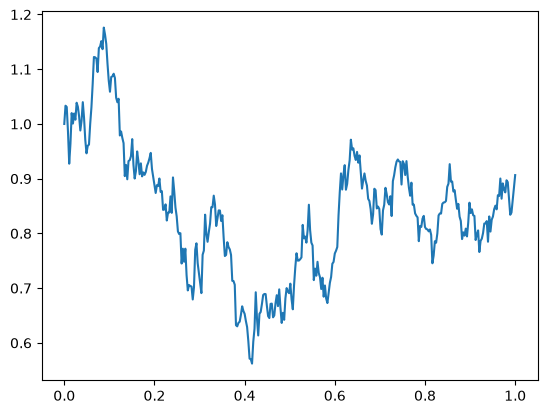

In [41]:
path_risque=risky_asset(T_test,n_test,tendance,r,volatilite)
plt.plot(t,path_risque)
plt.show()

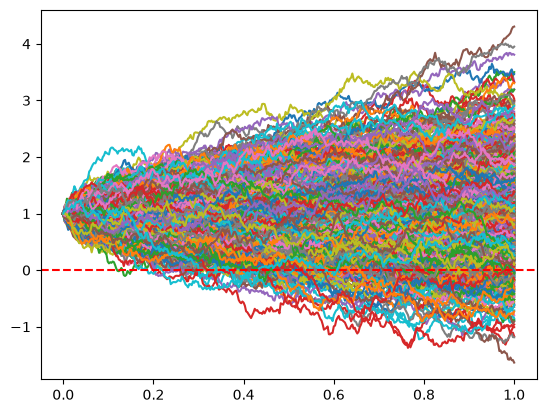

In [49]:
for i in range(1000):
    S= risky_asset(T_test,n_test,tendance,r,volatilite)
    plt.plot(t,S)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label="Barrière $S = 0$")
plt.show()

## Black-Scholes

2. Actif risqué

In [15]:
# parametres de simulation
volatilite = 0.2
tendance = 0.08

def prix_actif_risque(T, n, tendance, taux_interet, sigma):
    dt = T/n
    S = np.zeros(n+1)
    S_tilde = np.zeros(n+1)
    S[0] = S_zero
    S_tilde[0] = S_zero
    brownian = Brownian_path(T,n) 
    for i in range(1,n+1):
        S[i] = S[0] * np.exp((tendance - 0.5 * sigma**2) * i * dt + sigma * brownian[i])
    for i in range(1,n+1):
        S_tilde[i] = S_tilde[0] * np.exp((tendance - taux_interet - 0.5 * sigma**2) * i * dt + sigma * brownian[i])
    return S,S_tilde

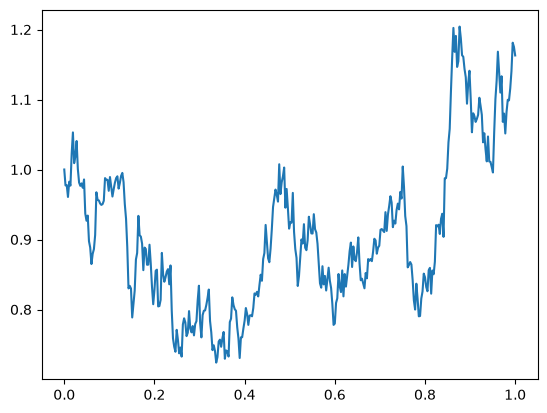

In [45]:
path_risque, path_risque_actualise=prix_actif_risque(T_test,n_test,tendance,r,volatilite)
plt.plot(t,path_risque)
plt.show()

3. Actif risqué actualisé

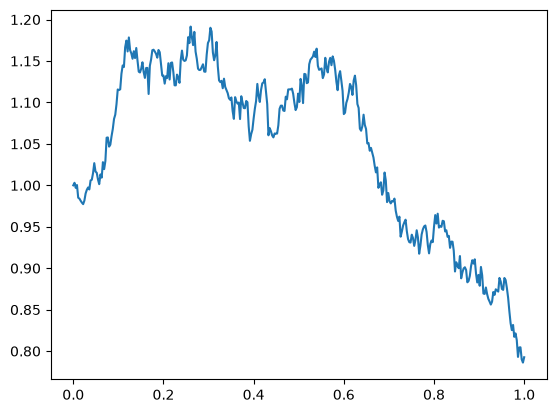

In [17]:
plt.plot(t, path_risque_actualise)
plt.show()

## 4. Simulation

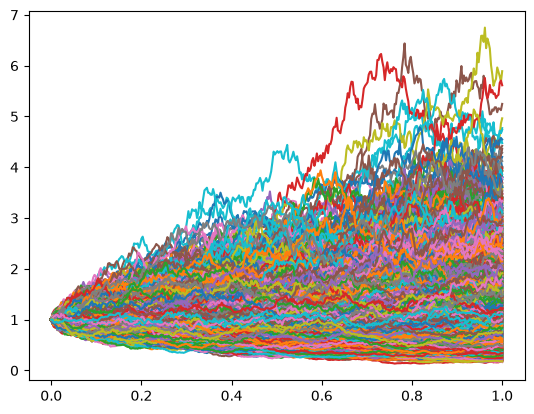

In [46]:
for i in range(10000):
    S,S_act = prix_actif_risque(T_test,n_test,tendance,r,volatilite)
    plt.plot(t,S_act)
plt.show()

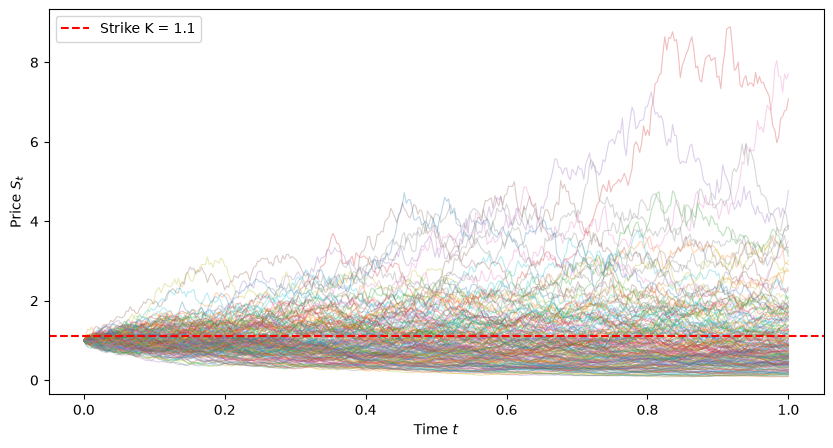

Monte Carlo Price Call : 0.2871


In [50]:
K = 1.10 
payoffs = np.zeros(10000)

plt.figure(figsize=(10, 5))
for i in range(10000):
    S, S_act = prix_actif_risque(T_test, n_test, r, r, volatilite)
    
    payoffs[i] = np.maximum(S[-1] - K, 0)
    
    if i < 200:
        plt.plot(t, S, alpha=0.3, linewidth=0.8)
call_price = np.exp(-r * T_test) * payoffs.mean()

plt.axhline(K, color='red', linestyle='--', linewidth=1.5, label=f"Strike K = {K}")
plt.xlabel("Time $t$")
plt.ylabel("Price $S_t$")
plt.legend()
plt.show()

print(f"Monte Carlo Price Call : {call_price:.4f}")

### Stratégie d'investissement 

In [ ]:
def investment_strat(stock, stock_act, nonrisky, p,capital):
    nb_parts_sans_risque = (capital * (1 - p)) / nonrisky[0]
    nb_parts_risque = (capital * p) / stock[0]

    X_T = nb_parts_sans_risque * nonrisky[-1] + nb_parts_risque * stock[-1]
    X_tilde_T = (capital / nonrisky[0]) + nb_parts_risque * (stock_act[-1] - stock_act[0])
    gain = X_tilde_T - capital
    return X_T, X_tilde_T, gain

In [ ]:
stock, stock_act= prix_actif_risque(T_test,n_test,tendance,r,volatilite)
p = 0.5
capital = 100
invest, invest_act, gain = investment_strat(stock, stock_act, risk_free_asset(T_test,n_test,r), p,capital)
print(gain)

-6.0044005363616435


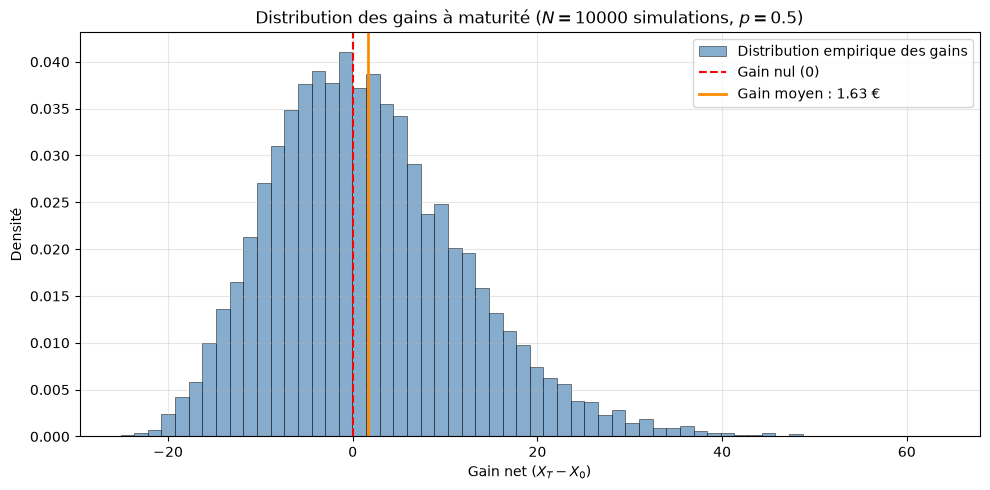

In [ ]:
p = 0.5
capital = 100
s_0=risk_free_asset(T_test,n_test,r)
gains=[]
for i in range(10000):
    stock, stock_act= prix_actif_risque(T_test,n_test,tendance,r,volatilite)
    invest, invest_act, gain = investment_strat(stock, stock_act, s_0 , p,capital)
    gains.append(gain)
plt.figure(figsize=(10, 5))
plt.hist(gains, bins=60, density=True, alpha=0.65, color="steelblue", edgecolor="black", linewidth=0.5, label="Distribution empirique des gains")

plt.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Gain nul ($0$)")
plt.axvline(np.mean(gains), color="darkorange", linestyle="-", linewidth=2, label=f"Gain moyen : {np.mean(gains):.2f} €")

plt.title(f"Distribution des gains à maturité ($N = {len(gains)}$ simulations, $p = {p}$)")
plt.xlabel("Gain net ($X_T - X_0$)")
plt.ylabel("Densité")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()